***Cell 1: Install***

In [1]:
# Cell 1: Install
!pip install -q qiskit==1.2.4 qiskit-machine-learning==0.8.0 qiskit-algorithms==0.3.0 scikit-image opencv-python-headless

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.4/133.4 kB 5.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.8/4.8 MB 27.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 237.5/237.5 kB 9.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 308.6/308.6 kB 10.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 58.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.6/49.6 MB 7.6 MB/s eta 0:00:00


***Cell 2: Dataset***

In [2]:
# Cell 2: Dataset
from google.colab import drive, files
drive.mount('/content/drive')

!unzip -q "/content/drive/MyDrive/Plant Disease.zip" -d /content/PlantVillage
!ls /content/PlantVillage

Mounted at /content/drive
plantvillage  PlantVillage


***Cell 3: Imports, settings, features***

In [3]:
# Cell 3: Imports, settings, features
import os, cv2, time, json, joblib, hashlib, shutil
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from skimage.feature import hog
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.metrics import ConfusionMatrixDisplay

BASE = None
for root, dirs, _ in os.walk("/content/PlantVillage"):
    if any(d.lower().startswith(("potato", "tomato", "pepper")) for d in dirs):
        BASE = root; break
ALL_CLASSES = sorted(c for c in os.listdir(BASE)
                     if c.lower().startswith(("potato", "tomato", "pepper")))
CLASSES = [c for c in ALL_CLASSES if c.lower().startswith("potato")]   # Potato only
print("BASE:", BASE)
print("CLASSES (Potato):", CLASSES)

N = 100        # images per class (same as Classical)
Q_TRAIN = 120  # training images for ALL models (simulator is slow). Test stays the same 60 images.

def features(img):
    img = cv2.resize(img, (64, 64))
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    h = hog(gray, pixels_per_cell=(16, 16))
    hist = cv2.calcHist([img], [0, 1, 2], None, [4, 4, 4], [0, 256] * 3).flatten()
    return np.concatenate([h, hist])

BASE: /content/PlantVillage/PlantVillage
CLASSES (Potato): ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']


***Cell 4: Explore***

Potato___Early_blight 1000
Potato___Late_blight 1000
Potato___healthy 152


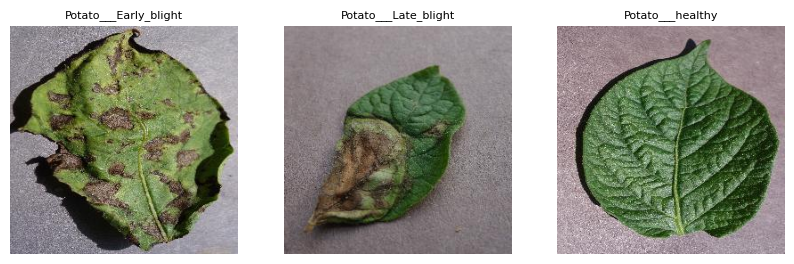

In [4]:
# Cell 4: Explore
for c in CLASSES:
    print(c, len(os.listdir(os.path.join(BASE, c))))

fig, ax = plt.subplots(1, len(CLASSES), figsize=(10, 3))
for i, c in enumerate(CLASSES):
    f = sorted(os.listdir(os.path.join(BASE, c)))[0]
    img = cv2.imread(os.path.join(BASE, c, f))
    ax[i].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax[i].set_title(c, fontsize=8); ax[i].axis("off")
plt.show()

***Cell 5: Cleaning***

In [5]:
# Cell 5: Cleaning
def clean_class(folder):
    seen, good = set(), []
    for f in sorted(os.listdir(folder)):
        p = os.path.join(folder, f)
        img = cv2.imread(p)
        if img is None: continue                     # corrupted image
        h = hashlib.md5(img.tobytes()).hexdigest()
        if h in seen: continue                       # duplicate image
        seen.add(h); good.append(p)
    return good

paths = {c: clean_class(os.path.join(BASE, c)) for c in CLASSES}
for c in CLASSES: print(c, "clean images:", len(paths[c]))

Potato___Early_blight clean images: 1000
Potato___Late_blight clean images: 1000
Potato___healthy clean images: 152


***Cell 6: Split and features***

In [6]:
# Cell 6: Split and features
all_p, all_y = [], []
for label, c in enumerate(CLASSES):
    sel = paths[c][:N]
    all_p += sel; all_y += [label] * len(sel)

# same split as Classical (random_state=42): same 60 test images
ptr, pte, ytr, yte = train_test_split(all_p, all_y, test_size=0.2,
                                      random_state=42, stratify=all_y)
# smaller training set for the quantum simulator (stratified)
ptr, _, ytr, _ = train_test_split(ptr, ytr, train_size=Q_TRAIN,
                                  random_state=42, stratify=ytr)

def extract(plist):
    return np.array([features(cv2.imread(p)) for p in plist])

Xtr = extract(ptr); y_tr = np.array(ytr)
Xte = extract(pte); y_te = np.array(yte)
print("Train:", Xtr.shape, "Test:", Xte.shape)

Train: (120, 388) Test: (60, 388)


***Cell 7: Scaling, PCA 4, scale to [0, π]***

In [7]:
# Cell 7: Scaling, PCA 4, scale to [0, π]
scaler = StandardScaler().fit(Xtr)
pca = PCA(n_components=4).fit(scaler.transform(Xtr))
print("Variance kept:", pca.explained_variance_ratio_.sum())
Ztr = pca.transform(scaler.transform(Xtr))
mm = MinMaxScaler((0, np.pi)).fit(Ztr)
prep = lambda X: np.clip(mm.transform(pca.transform(scaler.transform(X))), 0, np.pi)
Xtr, Xte = prep(Xtr), prep(Xte)      # all models use these same 4 features

os.makedirs("out", exist_ok=True)
joblib.dump((scaler, pca, mm), "out/preprocess.pkl")
json.dump(CLASSES, open("out/classes.json", "w"))
np.savez("out/split.npz", Xtr=Xtr, Xte=Xte, ytr=y_tr, yte=y_te)

Variance kept: 0.3261136231072173


***Cell 8: Evaluation helper***

In [8]:
# Cell 8: Evaluation helper
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import learning_curve
results = {}
def evaluate(name, model, kind, curve=None):
    t = time.time(); model.fit(Xtr, y_tr); tt = time.time() - t
    p = model.predict(Xte)
    results[name] = dict(type=kind, accuracy=accuracy_score(y_te, p),
        precision=precision_score(y_te, p, average="macro", zero_division=0),
        recall=recall_score(y_te, p, average="macro", zero_division=0),
        f1=f1_score(y_te, p, average="macro", zero_division=0),
        train_time_sec=tt, confusion=confusion_matrix(y_te, p).tolist(),
        curve=curve if curve is not None else [])
    print(name, {k: round(v, 3) for k, v in results[name].items() if isinstance(v, float)})
    return model
def add_lc(name, model):
    s, tr, va = learning_curve(model, Xtr, y_tr, cv=3, train_sizes=[0.4, 0.6, 0.8, 1.0], scoring="accuracy", shuffle=True, random_state=42)
    results[name]["learning"] = dict(sizes=s.tolist(), train=tr.mean(1).tolist(), val=va.mean(1).tolist())

***Cell 9: Classical models***

In [9]:
# Cell 9: Classical models
grids = {
  "SVM": (SVC(probability=True, random_state=42), {"C": [0.1, 1, 10], "kernel": ["rbf", "linear"]}),
  "RandomForest": (RandomForestClassifier(random_state=42),
                   {"n_estimators": [100, 200], "max_depth": [None, 5, 10]}),
  "MLP": (MLPClassifier(max_iter=1000, random_state=42),
          {"hidden_layer_sizes": [(32,), (32, 16)], "alpha": [0.0001, 0.01]}),
}
best = {}
for name, (m, g) in grids.items():
    gs = GridSearchCV(m, g, cv=5, scoring="f1_macro", n_jobs=-1).fit(Xtr, y_tr)
    best[name] = gs.best_estimator_
    print(name, gs.best_params_, "CV F1:", round(gs.best_score_, 3))

svm = evaluate("SVM", best["SVM"], "classical")
rf  = evaluate("Random Forest", best["RandomForest"], "classical")
mlp = evaluate("MLP", best["MLP"], "classical")
for n, m in [("SVM", svm), ("Random Forest", rf), ("MLP", mlp)]:
    add_lc(n, m)

SVM {'C': 1, 'kernel': 'linear'} CV F1: 0.653
RandomForest {'max_depth': 5, 'n_estimators': 100} CV F1: 0.604


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


MLP {'alpha': 0.0001, 'hidden_layer_sizes': (32,)} CV F1: 0.644
SVM {'accuracy': 0.633, 'precision': 0.634, 'recall': 0.633, 'f1': 0.623, 'train_time_sec': 0.003}
Random Forest {'accuracy': 0.567, 'precision': 0.566, 'recall': 0.567, 'f1': 0.566, 'train_time_sec': 0.106}


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


MLP {'accuracy': 0.567, 'precision': 0.567, 'recall': 0.567, 'f1': 0.565, 'train_time_sec': 0.303}


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perce

***Cell 10: qml_runtime.py  (pickle-free quantum inference, also used on Render)***

In [10]:
# Cell 10: qml_runtime.py  (pickle-free quantum inference, also used on Render)
%%writefile qml_runtime.py
"""
qml_runtime.py - pickle-free inference for QSVM / VQC / QNN.
Needs only: qiskit, numpy, scikit-learn, joblib  (no qiskit-machine-learning, no dill).
Works on any Python version that can install qiskit, so Colab and Render no longer have to match.
"""
from pathlib import Path
import numpy as np
import joblib
from qiskit import QuantumCircuit
from qiskit.circuit.library import ZZFeatureMap, RealAmplitudes
from qiskit.quantum_info import Statevector

NQ, NCLS = 4, 3          # 4 qubits (4 PCA features), 3 potato classes


def qsvm_feature_map():
    return ZZFeatureMap(NQ, reps=2, entanglement="linear")


def build_vqc_circuit():
    """Same circuit as VQC / SamplerQNN in the notebook: ZZFeatureMap(reps=1) + RealAmplitudes(reps=3)."""
    fm = ZZFeatureMap(NQ, reps=1)
    an = RealAmplitudes(NQ, reps=3)
    qc = QuantumCircuit(NQ)
    qc.compose(fm, inplace=True)
    qc.compose(an, inplace=True)
    return qc, list(fm.parameters), list(an.parameters)


class QNNRuntime:
    """Used for BOTH VQC and QNN (identical circuit; interpret = bitstring % 3)."""
    def __init__(self, weights):
        self.w = np.asarray(weights, dtype=float).ravel()
        self.qc, self.xp, self.wp = build_vqc_circuit()
        if len(self.w) != len(self.wp):
            raise ValueError(f"weights has {len(self.w)} values, circuit needs {len(self.wp)}")
        self.idx = np.arange(2 ** NQ) % NCLS

    def predict_proba(self, X):
        out = []
        for x in np.asarray(X, dtype=float).reshape(-1, NQ):
            bind = {p: float(v) for p, v in zip(self.xp, x)}
            bind.update({p: float(v) for p, v in zip(self.wp, self.w)})
            probs = Statevector(self.qc.assign_parameters(bind)).probabilities()
            out.append(np.bincount(self.idx, weights=probs, minlength=NCLS))
        return np.array(out)

    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)


class QSVMRuntime:
    """Quantum kernel K(x, y) = |<phi(x)|phi(y)>|^2 computed exactly with statevectors + saved sklearn SVC."""
    def __init__(self, svc, Xtr):
        self.svc = svc
        self.fm = qsvm_feature_map()
        self.params = list(self.fm.parameters)
        self.Xtr = np.asarray(Xtr, dtype=float)
        self.T = np.array([self._state(x) for x in self.Xtr])      # train states, computed once

    def _state(self, x):
        bound = self.fm.assign_parameters({p: float(v) for p, v in zip(self.params, x)})
        return Statevector(bound).data

    def kernel(self, X):
        S = np.array([self._state(x) for x in np.asarray(X, dtype=float).reshape(-1, NQ)])
        return np.abs(S.conj() @ self.T.T) ** 2

    def predict(self, X):
        return self.svc.predict(self.kernel(X))

    def predict_proba(self, X):
        return self.svc.predict_proba(self.kernel(X))


def load(name, folder="."):
    folder = Path(folder)
    if name == "QSVM":
        return QSVMRuntime(joblib.load(folder / "qsvm_svc.pkl"), np.load(folder / "qsvm_train_X.npy"))
    if name == "VQC":
        return QNNRuntime(np.load(folder / "vqc_weights.npy"))
    if name == "QNN":
        return QNNRuntime(np.load(folder / "qnn_weights.npy"))
    raise ValueError(name)

Writing qml_runtime.py


***Cell 11: QSVM (Quantum Support Vector Machine)  - quantum kernel + SVC, saved without pickling qiskit objects***

In [11]:
# Cell 11: QSVM (Quantum Support Vector Machine)  - quantum kernel + SVC, saved without pickling qiskit objects
import qml_runtime as qml
from qiskit.circuit.library import ZZFeatureMap, RealAmplitudes
from qiskit_machine_learning.algorithms import VQC, NeuralNetworkClassifier
from qiskit_machine_learning.kernels import FidelityQuantumKernel
from qiskit_algorithms.optimizers import COBYLA

class QSVMClf:
    """Same as QSVC: FidelityQuantumKernel + SVC(kernel='precomputed')."""
    def __init__(s):
        s.qk = FidelityQuantumKernel(feature_map=qml.qsvm_feature_map())
    def fit(s, X, y):
        s.Xfit = np.array(X)
        K = s.qk.evaluate(s.Xfit)
        s.svc = SVC(kernel="precomputed", probability=True, random_state=42).fit(K, y)
        return s
    def predict(s, X):
        return s.svc.predict(s.qk.evaluate(np.array(X), s.Xfit))

qsvm = evaluate("QSVM", QSVMClf(), "quantum")

QSVM {'accuracy': 0.4, 'precision': 0.374, 'recall': 0.4, 'f1': 0.375, 'train_time_sec': 25.739}


***Cell 12: VQC (Variational Quantum Classifier)***

In [12]:
# Cell 12: VQC (Variational Quantum Classifier)
loss_vqc = []
vqc = VQC(feature_map=ZZFeatureMap(4, reps=1), ansatz=RealAmplitudes(4, reps=3),
          optimizer=COBYLA(maxiter=100), callback=lambda w, f: loss_vqc.append(float(f)))
evaluate("VQC", vqc, "quantum", curve=loss_vqc)

VQC {'accuracy': 0.4, 'precision': 0.397, 'recall': 0.4, 'f1': 0.396, 'train_time_sec': 53.784}


***Cell 13: QNN (Quantum Neural Network)***

In [13]:
# Cell 13: QNN (Quantum Neural Network)
from qiskit import QuantumCircuit
from qiskit_machine_learning.neural_networks import SamplerQNN
fm = ZZFeatureMap(4, reps=1); an = RealAmplitudes(4, reps=3)
qc = QuantumCircuit(4); qc.compose(fm, inplace=True); qc.compose(an, inplace=True)
qnn = SamplerQNN(circuit=qc, input_params=fm.parameters, weight_params=an.parameters,
                 interpret=lambda x: x % 3, output_shape=3)
loss_qnn = []
core = NeuralNetworkClassifier(qnn, loss="cross_entropy", one_hot=True,
        optimizer=COBYLA(maxiter=100), callback=lambda w, f: loss_qnn.append(float(f)))
class QNNClf:
    def __init__(s, c): s.c = c
    def fit(s, X, y): s.c.fit(X, np.eye(3)[y]); return s
    def predict(s, X): return np.argmax(s.c.predict(X), axis=1)
qnn_model = evaluate("QNN", QNNClf(core), "quantum", curve=loss_qnn)

/tmp/ipykernel_1886/3047230183.py:6: DeprecationWarning: V1 Primitives are deprecated as of qiskit-machine-learning 0.8.0 and will be removed no sooner than 4 months after the release date. Use V2 primitives for continued compatibility and support.
  qnn = SamplerQNN(circuit=qc, input_params=fm.parameters, weight_params=an.parameters,


QNN {'accuracy': 0.417, 'precision': 0.399, 'recall': 0.417, 'f1': 0.392, 'train_time_sec': 48.811}


***Cell 14: Results table, graphs, save (pickle-free for quantum models)***

,type,accuracy,precision,recall,f1,train_time_sec
SVM,classical,0.633,0.634,0.633,0.623,0.003
Random Forest,classical,0.567,0.566,0.567,0.566,0.106
MLP,classical,0.567,0.567,0.567,0.565,0.303
QSVM,quantum,0.400,0.374,0.400,0.375,25.739
VQC,quantum,0.400,0.397,0.400,0.396,53.784
QNN,quantum,0.417,0.399,0.417,0.392,48.811


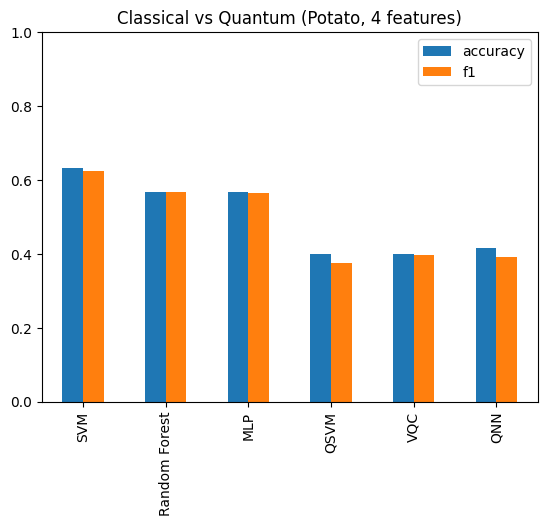

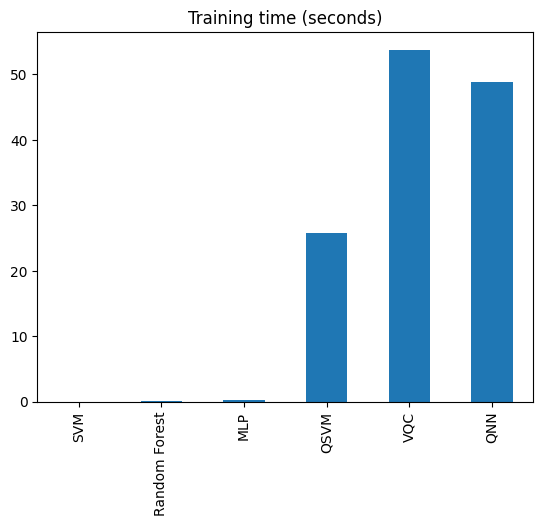

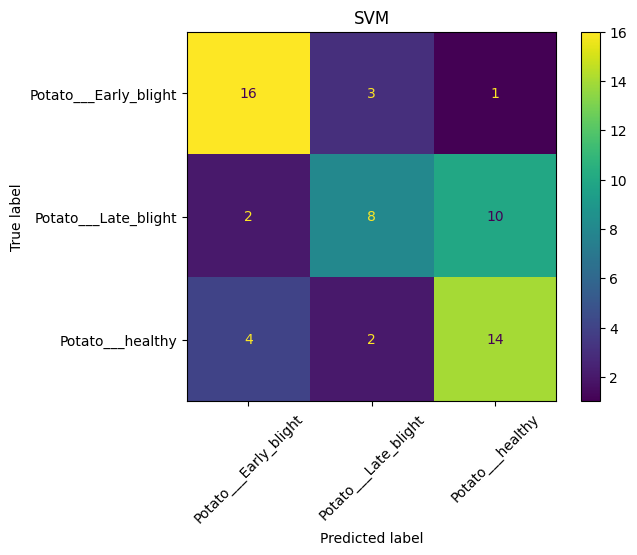

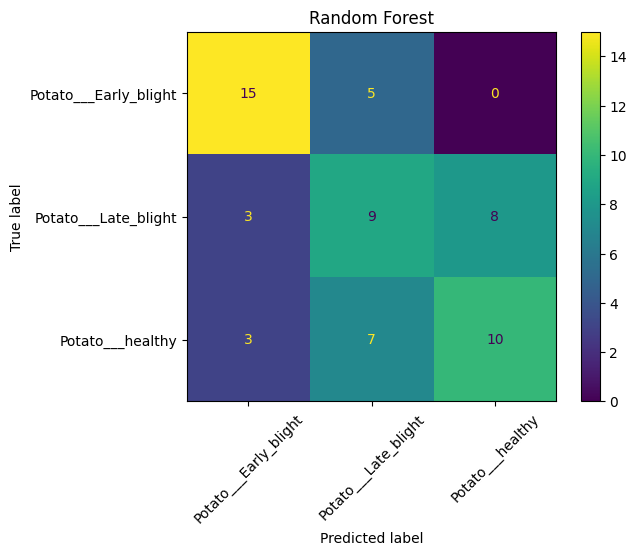

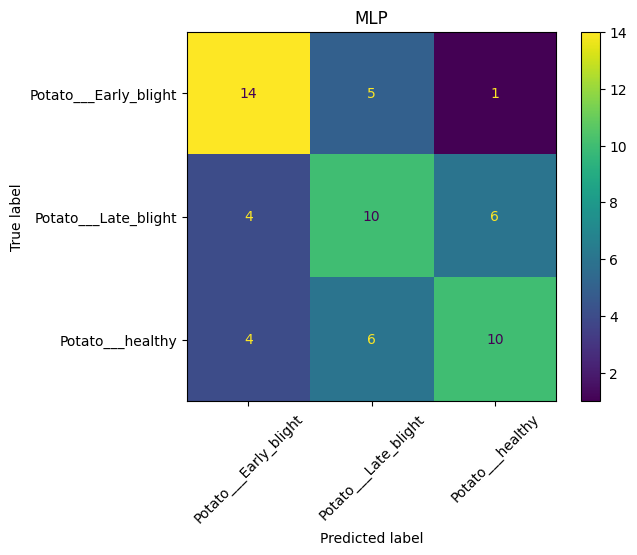

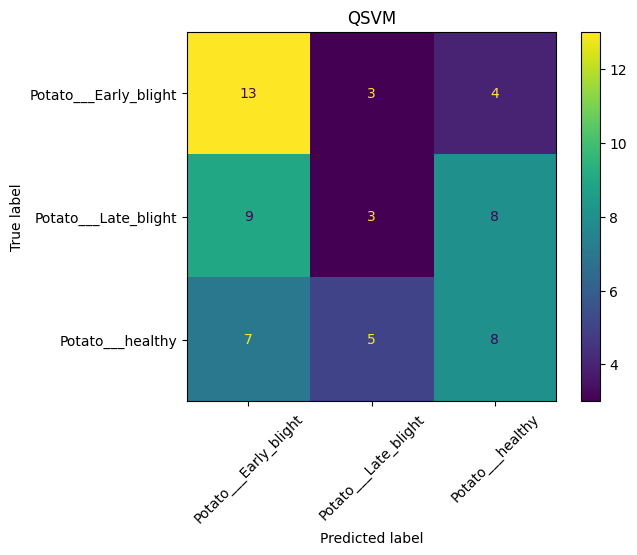

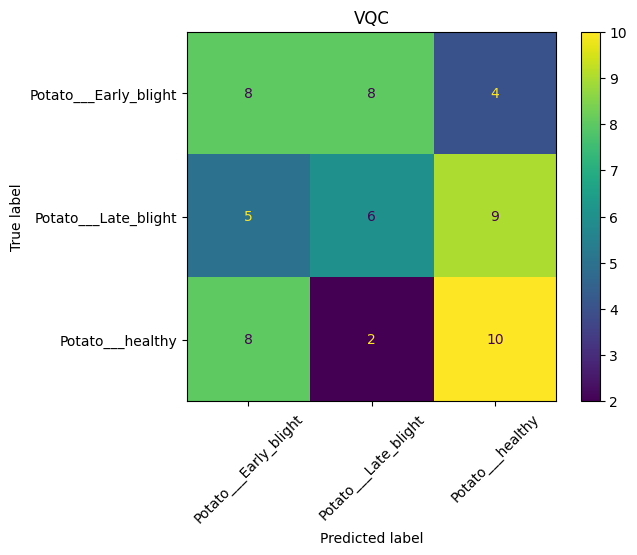

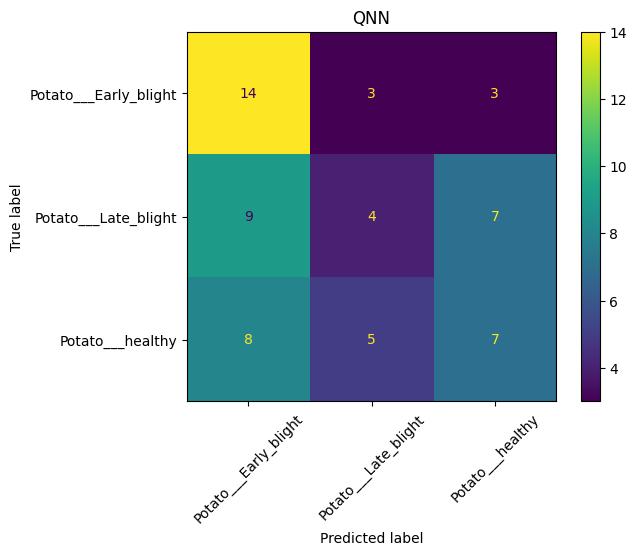

In [15]:
# Cell 14: Results table, graphs, save (pickle-free for quantum models)
df = pd.DataFrame(results).T[["type", "accuracy", "precision", "recall", "f1", "train_time_sec"]]
cols = ["accuracy", "precision", "recall", "f1", "train_time_sec"]
df[cols] = df[cols].astype(float).round(3)
display(df)
df.to_csv("out/comparison_results.csv")
json.dump(results, open("out/model_results.json", "w"))
for n, m in [("svm", svm), ("rf", rf), ("mlp", mlp)]:
    joblib.dump(m, f"out/{n}.pkl")

# quantum models: plain files only (no dill, no qiskit objects, no lambdas)
joblib.dump(qsvm.svc, "out/qsvm_svc.pkl")
np.save("out/qsvm_train_X.npy", qsvm.Xfit)
np.save("out/vqc_weights.npy", np.asarray(vqc.weights))
np.save("out/qnn_weights.npy", np.asarray(core.weights))
shutil.copy("qml_runtime.py", "out/qml_runtime.py")

df[["accuracy", "f1"]].plot(kind="bar", ylim=(0, 1), title="Classical vs Quantum (Potato, 4 features)")
plt.show()
df["train_time_sec"].plot(kind="bar", title="Training time (seconds)")
plt.show()
for n, r in results.items():
    ConfusionMatrixDisplay(np.array(r["confusion"]), display_labels=CLASSES).plot(xticks_rotation=45)
    plt.title(n); plt.show()

***Cell 15: CHECK - saved pickle-free models must give the same predictions as the trained ones***

In [16]:
# Cell 15: CHECK - saved pickle-free models must give the same predictions as the trained ones
def lab(p):
    p = np.asarray(p)
    return p.argmax(1) if p.ndim > 1 else p.astype(int)

ref = {"QSVM": lab(qsvm.predict(Xte)), "VQC": lab(vqc.predict(Xte)), "QNN": lab(qnn_model.predict(Xte))}
for n in ["QSVM", "VQC", "QNN"]:
    rt = qml.load(n, "out")
    pred = rt.predict(Xte)
    print(n, "match with trained model:", round(float((pred == ref[n]).mean()) * 100, 1), "%")

QSVM match with trained model: 100.0 %
VQC match with trained model: 100.0 %
QNN match with trained model: 100.0 %


***Cell 16: Samples and download***

In [17]:
# Cell 16: Samples and download
os.makedirs("out/samples", exist_ok=True)
for k, c in enumerate(CLASSES):
    for i, p in enumerate(paths[c][:3]):
        shutil.copy(p, f"out/samples/{c}_{i+1}.jpg")

!zip -qr quantum_outputs.zip out
files.download("quantum_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

***Cell 17: Predict one image with all 6 models***

In [21]:
# Cell 17: Predict one image with all 6 models
def predict_image(path):
    x = prep(np.array([features(cv2.imread(path))]))
    models = {"SVM": svm, "Random Forest": rf, "MLP": mlp,
              "QSVM": qsvm, "VQC": vqc, "QNN": qnn_model}
    out = {}
    for n, m in models.items():
        p = np.asarray(m.predict(x))
        label = int(lab(np.atleast_1d(p))[0])
        out[n] = CLASSES[label]
    return out

print(predict_image(pte[0]), "| true:", CLASSES[y_te[0]])

{'SVM': 'Potato___Early_blight', 'Random Forest': 'Potato___Early_blight', 'MLP': 'Potato___Early_blight', 'QSVM': 'Potato___Early_blight', 'VQC': 'Potato___healthy', 'QNN': 'Potato___Early_blight'} | true: Potato___Early_blight
